In [2]:

from pathlib import Path
import pandas as pd

# Project root folder
ROOT = Path.cwd().parent
RESULTS_DIR = ROOT / "results"

# Load metadata
face_metadata_df = pd.read_csv(
    RESULTS_DIR / "final_face_metadata.csv"
)

# Keep only existing images
face_metadata_df = face_metadata_df[
    face_metadata_df["file_exists"].astype(str).str.lower() == "true"
].copy()

# Create datasets
train_df = face_metadata_df[
    face_metadata_df["split"] == "train"
].reset_index(drop=True)

val_df = face_metadata_df[
    face_metadata_df["split"] == "val"
].reset_index(drop=True)

test_df = face_metadata_df[
    face_metadata_df["split"] == "test"
].reset_index(drop=True)

print("TRAIN:", len(train_df))
print("VALIDATION:", len(val_df))
print("TEST:", len(test_df))


TRAIN: 39450
VALIDATION: 9870
TEST: 12321


In [3]:
print("TRAIN:")
print(train_df["label"].value_counts())

print("\nVALIDATION:")
print(val_df["label"].value_counts())

print("\nTEST:")
print(test_df["label"].value_counts())

TRAIN:
label
1    33930
0     5520
Name: count, dtype: int64

VALIDATION:
label
1    8490
0    1380
Name: count, dtype: int64

TEST:
label
1    10610
0     1711
Name: count, dtype: int64


In [4]:
print(train_df["label"].value_counts())
print(val_df["label"].value_counts())
print(test_df["label"].value_counts())

label
1    33930
0     5520
Name: count, dtype: int64
label
1    8490
0    1380
Name: count, dtype: int64
label
1    10610
0     1711
Name: count, dtype: int64


In [5]:

print("LABEL 0 EXAMPLES:")
print(
    face_metadata_df[face_metadata_df["label"] == 0]
    [["video_path", "face_path", "label"]]
    .head(5).to_string(index=False)
)

print("\nLABEL 1 EXAMPLES:")
print(
    face_metadata_df[face_metadata_df["label"] == 1]
    [["video_path", "face_path", "label"]]
    .head(5).to_string(index=False)
)


LABEL 0 EXAMPLES:
                                                                                           video_path                                         face_path  label
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 results\processed_faces\real\id0_0000_face_00.jpg      0
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 results\processed_faces\real\id0_0000_face_01.jpg      0
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 results\processed_faces\real\id0_0000_face_02.jpg      0
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 results\processed_faces\real\id0_0000_face_03.jpg      0
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 results\processed_faces\real\id0_0000_face_04.jpg      0

LABEL 1 EXAMPLES:
         

In [6]:

from pathlib import Path


# Check image paths
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    existing = df["face_path"].apply(
        lambda p: (ROOT / p).exists()
        if not Path(p).is_absolute()
        else Path(p).exists()
    )

    print(f"{name}:")
    print("Total images:", len(df))
    print("Existing images:", existing.sum())
    print("Missing images:", (~existing).sum())
    print()


Train:
Total images: 39450
Existing images: 39450
Missing images: 0

Validation:
Total images: 9870
Existing images: 9870
Missing images: 0

Test:
Total images: 12321
Existing images: 12321
Missing images: 0



In [9]:

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from PIL import Image
from pathlib import Path
import numpy as np

# Device
device = torch.device("cpu")
print("Training device:", device)

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Dataset class
class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = Path(row["face_path"])

        if not path.is_absolute():
            path = ROOT / path

        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return image, label

# Create datasets
train_dataset = DeepfakeDataset(train_df, train_transform)
val_dataset = DeepfakeDataset(val_df, val_transform)
test_dataset = DeepfakeDataset(test_df, val_transform)

# Balanced sampling weights
labels = train_df["label"].to_numpy().astype(int)
class_counts = np.bincount(labels, minlength=2)

sample_weights = 1.0 / class_counts[labels]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    sampler=sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Class counts:", class_counts)
print("DataLoaders ready!")


Training device: cpu
Training batches: 4932
Validation batches: 1234
Test batches: 1541
Class counts: [ 5520 33930]
DataLoaders ready!


In [10]:

import copy
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from pathlib import Path

# CPU optimization
torch.set_num_threads(4)

# Load pretrained ResNet50
resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Freeze all layers first
for param in resnet50.parameters():
    param.requires_grad = False

# Replace classifier
num_features = resnet50.fc.in_features
resnet50.fc = nn.Linear(num_features, 1)

# Train layer4 and classifier
for param in resnet50.layer4.parameters():
    param.requires_grad = True

for param in resnet50.fc.parameters():
    param.requires_grad = True

resnet50 = resnet50.to(device)

# Loss and optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet50.parameters()),
    lr=0.0001,
    weight_decay=0.0001
)

# Training configuration
EPOCHS = 3
best_f1 = -1
best_state = None
patience = 2
no_improvement = 0

MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for epoch in range(EPOCHS):

    # Training
    resnet50.train()

    # Keep frozen BatchNorm layers in evaluation mode
    for module in resnet50.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(device)
        labels = labels.to(device).view(-1, 1)

        optimizer.zero_grad()

        outputs = resnet50(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if (batch_idx + 1) % 500 == 0:
            print(
                f"Epoch {epoch+1}/{EPOCHS} | "
                f"Batch {batch_idx+1}/{len(train_loader)}"
            )

    train_loss = running_loss / len(train_loader)

    # Validation
    resnet50.eval()

    y_true = []
    y_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device).view(-1, 1)

            outputs = resnet50(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item()

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).int()

            y_true.extend(labels.cpu().numpy().flatten())
            y_pred.extend(predictions.cpu().numpy().flatten())

    val_loss = val_loss_total / len(val_loader)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    print(f"\nEpoch {epoch+1} Results")
    print("Train Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Accuracy:", round(accuracy, 4))
    print("Precision (Fake):", round(precision, 4))
    print("Recall (Fake):", round(recall, 4))
    print("Macro F1:", round(f1, 4))

    # Save best model
    if f1 > best_f1:
        best_f1 = f1
        best_state = copy.deepcopy(resnet50.state_dict())

        torch.save(
            best_state,
            MODEL_DIR / "resnet50_deepfake_best.pth"
        )

        print("Best model checkpoint saved!")
        no_improvement = 0
    else:
        no_improvement += 1

    if no_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore best model
if best_state is not None:
    resnet50.load_state_dict(best_state)

print("\nTraining completed!")
print("Best validation Macro F1:", round(best_f1, 4))
print("Saved:", MODEL_DIR / "resnet50_deepfake_best.pth")


Epoch 1/3 | Batch 500/4932
Epoch 1/3 | Batch 1000/4932
Epoch 1/3 | Batch 1500/4932
Epoch 1/3 | Batch 2000/4932
Epoch 1/3 | Batch 2500/4932
Epoch 1/3 | Batch 3000/4932
Epoch 1/3 | Batch 3500/4932
Epoch 1/3 | Batch 4000/4932
Epoch 1/3 | Batch 4500/4932

Epoch 1 Results
Train Loss: 0.5529
Validation Loss: 0.788
Accuracy: 0.6331
Precision (Fake): 0.8896
Recall (Fake): 0.6548
Macro F1: 0.5151
Best model checkpoint saved!
Epoch 2/3 | Batch 500/4932
Epoch 2/3 | Batch 1000/4932
Epoch 2/3 | Batch 1500/4932
Epoch 2/3 | Batch 2000/4932
Epoch 2/3 | Batch 2500/4932
Epoch 2/3 | Batch 3000/4932
Epoch 2/3 | Batch 3500/4932
Epoch 2/3 | Batch 4000/4932
Epoch 2/3 | Batch 4500/4932


KeyboardInterrupt: 

In [24]:
import torch
from pathlib import Path

checkpoint_path = ROOT / "models" / "training_resume_checkpoint.pth"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({
    "epoch": epoch + 1,
    "model_state_dict": resnet50.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_f1": best_f1
}, checkpoint_path)

print("Resume checkpoint saved:", checkpoint_path)

NameError: name 'epoch' is not defined

In [ ]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

print("Next epoch:", checkpoint["epoch"] + 1)
print("Best F1:", checkpoint["best_f1"])

Next epoch: 3
Best F1: 0.5151350352766817


In [ ]:
from pathlib import Path

model_dir = ROOT / "models"

for file in model_dir.glob("*.pth"):
    print(file.name, round(file.stat().st_size / (1024 * 1024), 2), "MB")

resnet50_deepfake.pth 89.99 MB
resnet50_deepfake_best.pth 89.99 MB
training_resume_checkpoint.pth 204.2 MB
week4_resnet50.pth 89.99 MB


In [23]:
checkpoint_path = ROOT / "models" / "training_resume_checkpoint.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

resnet50.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

start_epoch = checkpoint["epoch"]
best_f1 = checkpoint["best_f1"]

print("Resuming from epoch:", start_epoch + 1)
print("Best F1:", best_f1)

Resuming from epoch: 3
Best F1: 0.5151350352766817


In [9]:
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path

print("PyTorch version:", torch.__version__)
print("Ready!")

PyTorch version: 2.14.1+cpu
Ready!


In [22]:
import torch
from pathlib import Path

checkpoint_path = ROOT / "models" / "training_resume_checkpoint.pth"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({
    "epoch": epoch + 1,
    "model_state_dict": resnet50.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_f1": best_f1
}, checkpoint_path)

print("Resume checkpoint saved:", checkpoint_path)

NameError: name 'epoch' is not defined

In [12]:
import torch

checkpoint_path = ROOT / "models" / "training_resume_checkpoint.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Saved epoch:", checkpoint["epoch"])
print("Best F1:", checkpoint["best_f1"])

Saved epoch: 2
Best F1: 0.5151350352766817


In [14]:
import torch

device = torch.device("cpu")

print("Device:", device)

Device: cpu


In [16]:

from torchvision import models
import torch.nn as nn

resnet50 = models.resnet50(weights=None)

num_features = resnet50.fc.in_features
resnet50.fc = nn.Linear(num_features, 1)

resnet50 = resnet50.to(device)

print("ResNet50 model ready!")

ResNet50 model ready!


In [19]:
import torch.optim as optim

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet50.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer ready!")

Optimizer ready!


In [21]:
checkpoint = torch.load(
    ROOT / "models" / "training_resume_checkpoint.pth",
    map_location=device,
    weights_only=True
)

resnet50.load_state_dict(checkpoint["model_state_dict"])
# Restore the same trainable-layer configuration used by the original training run
for param in resnet50.parameters():
    param.requires_grad = False

for param in resnet50.layer4.parameters():
    param.requires_grad = True

for param in resnet50.fc.parameters():
    param.requires_grad = True

# Recreate the optimizer with the same parameter selection
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet50.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

start_epoch = checkpoint["epoch"]
best_f1 = checkpoint["best_f1"]

EPOCHS = 3

print("Starting Epoch:", start_epoch + 1)
print("Best F1:", best_f1)

Starting Epoch: 3
Best F1: 0.5151350352766817


In [29]:
print("Train batch size:", train_loader.batch_size)
print("Validation batch size:", val_loader.batch_size)
print("Train sampler:", type(train_loader.sampler).__name__)
print("Starting epoch:", start_epoch + 1)

Train batch size: 16
Validation batch size: 16
Train sampler: RandomSampler
Starting epoch: 3


In [28]:

import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score
)

MODEL_DIR = ROOT / "models"
RESUME_PATH = MODEL_DIR / "training_resume_checkpoint.pth"
BEST_MODEL_PATH = MODEL_DIR / "resnet50_deepfake_best.pth"

EPOCHS = 3
criterion = nn.BCEWithLogitsLoss()

print("Starting Epoch:", start_epoch + 1)
print("Previous Best F1:", best_f1)

# Use the original train_loader and val_loader.
# Do not recreate them here.

for epoch in range(start_epoch, EPOCHS):

    resnet50.train()

    for module in resnet50.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device).view(-1, 1)

        optimizer.zero_grad()
        outputs = resnet50(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if (batch_idx + 1) % 500 == 0:
            print(
                f"Epoch {epoch+1}/{EPOCHS} | "
                f"Batch {batch_idx+1}/{len(train_loader)}"
            )

    train_loss = running_loss / len(train_loader)

    # Validation
    resnet50.eval()
    y_true, y_pred = [], []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).view(-1, 1)

            outputs = resnet50(images)
            loss = criterion(outputs, labels)
            val_loss_total += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).int()

            y_true.extend(labels.cpu().numpy().flatten())
            y_pred.extend(predictions.cpu().numpy().flatten())

    val_loss = val_loss_total / len(val_loader)
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(
        y_true, y_pred,
        average="macro", zero_division=0
    )

    print(f"\nEpoch {epoch+1} Results")
    print("Train Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Accuracy:", round(accuracy, 4))
    print("Precision (Fake):", round(precision, 4))
    print("Recall (Fake):", round(recall, 4))
    print("Macro F1:", round(f1, 4))

    if f1 > best_f1:
        best_f1 = f1
        torch.save(resnet50.state_dict(), BEST_MODEL_PATH)
        print("Best model checkpoint updated!")

    # Save resume checkpoint after completed epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": resnet50.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_f1": best_f1
    }, RESUME_PATH)

    print("Resume checkpoint saved!")

print("\nTraining completed!")
print("Best validation Macro F1:", round(best_f1, 4))


Starting Epoch: 3
Previous Best F1: 0.5151350352766817
Epoch 3/3 | Batch 500/2466
Epoch 3/3 | Batch 1000/2466
Epoch 3/3 | Batch 1500/2466
Epoch 3/3 | Batch 2000/2466

Epoch 3 Results
Train Loss: 0.2277
Validation Loss: 0.7398
Accuracy: 0.8781
Precision (Fake): 0.8823
Recall (Fake): 0.9905
Macro F1: 0.6167
Best model checkpoint updated!
Resume checkpoint saved!

Training completed!
Best validation Macro F1: 0.6167


In [30]:
print("start_epoch =", start_epoch)
print("Next epoch =", start_epoch + 1)
print("best_f1 =", best_f1)
print("Train batches =", len(train_loader))
print("Batch size =", train_loader.batch_size)
print("Sampler =", type(train_loader.sampler).__name__)

start_epoch = 2
Next epoch = 3
best_f1 = 0.6167095340485548
Train batches = 2466
Batch size = 16
Sampler = RandomSampler


In [31]:
from pathlib import Path

model_dir = ROOT / "models"

for name in [
    "resnet50_deepfake_best.pth",
    "training_resume_checkpoint.pth"
]:
    path = model_dir / name
    print(name, "Exists:", path.exists())

    if path.exists():
        print("Size:", round(path.stat().st_size / (1024 * 1024), 2), "MB")

resnet50_deepfake_best.pth Exists: True
Size: 89.99 MB
training_resume_checkpoint.pth Exists: True
Size: 204.2 MB


In [34]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import torch

class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = Path(str(row["face_path"]))

        if not image_path.is_absolute():
            image_path = ROOT / image_path

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if self.transform:
                image = self.transform(image)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return image, label

In [36]:
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [37]:
from torch.utils.data import DataLoader

test_dataset = DeepfakeDataset(test_df, val_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Test DataLoader ready!")

Test samples: 12321
Test batches: 1541
Test DataLoader ready!


In [38]:

import torch
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Load the best trained model
best_model_path = ROOT / "models" / "resnet50_deepfake_best.pth"

resnet50.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)
resnet50.eval()

y_true = []
y_pred = []
y_scores = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = resnet50(images)
        probabilities = torch.sigmoid(outputs).cpu().numpy().flatten()
        predictions = (probabilities >= 0.5).astype(int)

        y_true.extend(labels.numpy().flatten().astype(int))
        y_pred.extend(predictions)
        y_scores.extend(probabilities)

print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("ROC-AUC:", round(roc_auc_score(y_true, y_scores), 4))


Test Accuracy: 0.8793

Classification Report:
              precision    recall  f1-score   support

        Real       0.75      0.19      0.31      1711
        Fake       0.88      0.99      0.93     10610

    accuracy                           0.88     12321
   macro avg       0.82      0.59      0.62     12321
weighted avg       0.87      0.88      0.85     12321

Confusion Matrix:
[[  332  1379]
 [  108 10502]]
ROC-AUC: 0.595


In [39]:

import numpy as np
import torch
from sklearn.metrics import f1_score

resnet50.eval()

val_true = []
val_scores = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = resnet50(images)
        probabilities = torch.sigmoid(outputs).cpu().numpy().flatten()

        val_true.extend(labels.numpy().flatten().astype(int))
        val_scores.extend(probabilities)

val_true = np.array(val_true)
val_scores = np.array(val_scores)

best_threshold = 0.5
best_macro_f1 = 0

for threshold in np.arange(0.05, 0.96, 0.01):
    predictions = (val_scores >= threshold).astype(int)

    score = f1_score(
        val_true,
        predictions,
        average="macro",
        zero_division=0
    )

    if score > best_macro_f1:
        best_macro_f1 = score
        best_threshold = threshold

print("Best validation threshold:", round(best_threshold, 2))
print("Best validation Macro F1:", round(best_macro_f1, 4))


Best validation threshold: 0.75
Best validation Macro F1: 0.6416


In [40]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

TEST_THRESHOLD = 0.75

y_pred_tuned = (
    np.array(y_scores) >= TEST_THRESHOLD
).astype(int)

print("Test Threshold:", TEST_THRESHOLD)
print("Test Accuracy:", round(
    accuracy_score(y_true, y_pred_tuned), 4
))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_tuned,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true, y_pred_tuned, labels=[0, 1]
))

print("ROC-AUC:", round(
    roc_auc_score(y_true, y_scores), 4
))


Test Threshold: 0.75
Test Accuracy: 0.8606

Classification Report:
              precision    recall  f1-score   support

        Real       0.50      0.27      0.35      1711
        Fake       0.89      0.96      0.92     10610

    accuracy                           0.86     12321
   macro avg       0.69      0.61      0.63     12321
weighted avg       0.84      0.86      0.84     12321

Confusion Matrix:
[[  456  1255]
 [  463 10147]]
ROC-AUC: 0.595


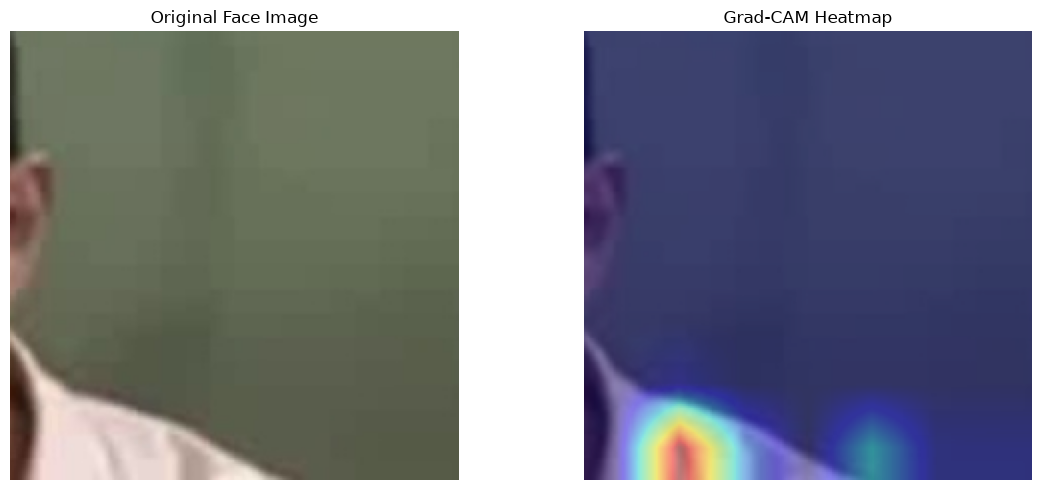

Actual Label: Real
Predicted: Fake
Grad-CAM generated successfully!


In [41]:

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Select one test image
sample = test_df.iloc[0]
image_path = Path(str(sample["face_path"]))

if not image_path.is_absolute():
    image_path = ROOT / image_path

# Load image and transform
image = Image.open(image_path).convert("RGB")
input_tensor = val_transform(image).unsqueeze(0).to(device)

resnet50.eval()

gradients = []
activations = []

def save_gradient(gradient):
    gradients.append(gradient)

def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_gradient)

# ResNet50 final convolutional layer
target_layer = resnet50.layer4[-1].conv3
handle = target_layer.register_forward_hook(forward_hook)

resnet50.zero_grad()

output = resnet50(input_tensor)
score = output[0, 0]
score.backward()

handle.remove()

# Grad-CAM calculation
weights = gradients[0].mean(dim=(2, 3), keepdim=True)
cam = (weights * activations[0]).sum(dim=1, keepdim=True)
cam = F.relu(cam)

cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam.squeeze().detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() + 1e-8)

# Original image
original = np.array(image.resize((224, 224)))

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Face Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original)
plt.imshow(cam, cmap="jet", alpha=0.45)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual Label:", "Fake" if int(sample["label"]) == 1 else "Real")
print("Predicted:", "Fake" if torch.sigmoid(output).item() >= 0.75 else "Real")
print("Grad-CAM generated successfully!")
